<a href="https://colab.research.google.com/github/ri27haha/codealpha_audioplayer/blob/main/Copy_of_Untitled10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Loading data... This might take a moment.

--- KPI SUMMARY ---
Total Enrollments: 10000
Total Unique Learners: 3000
Total Unique Courses: 60
Average Courses per Learner: 3.33


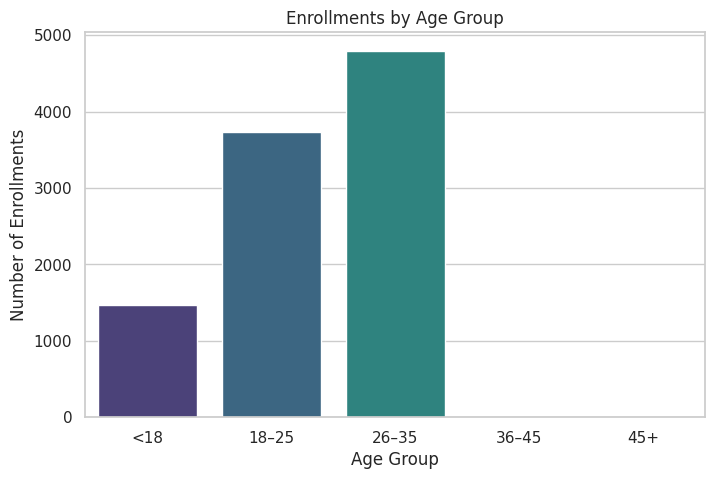

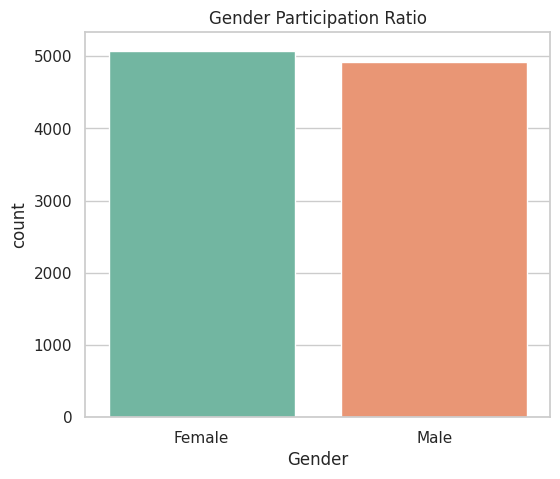

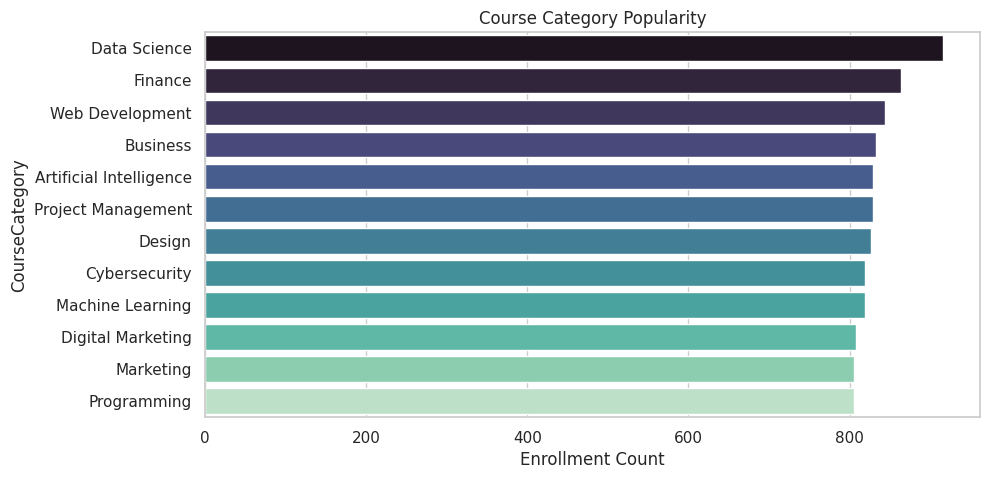

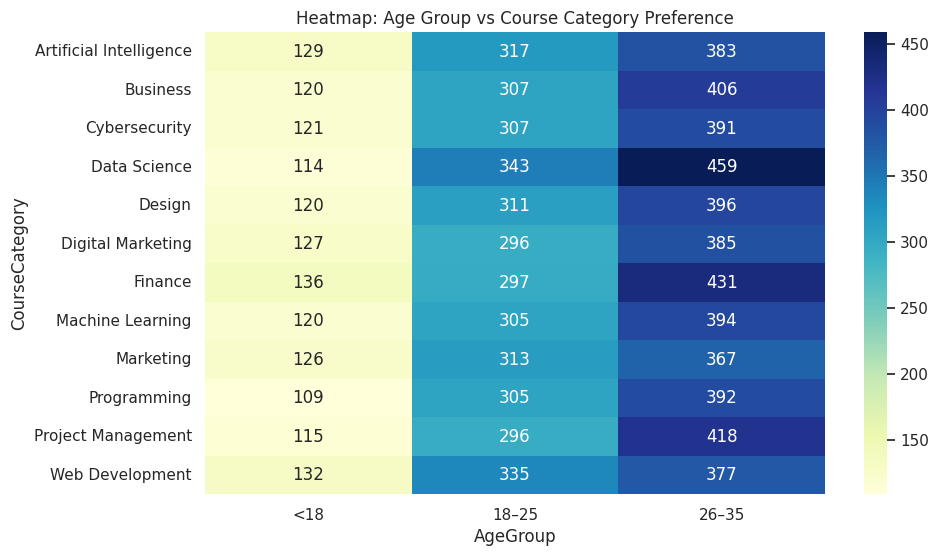

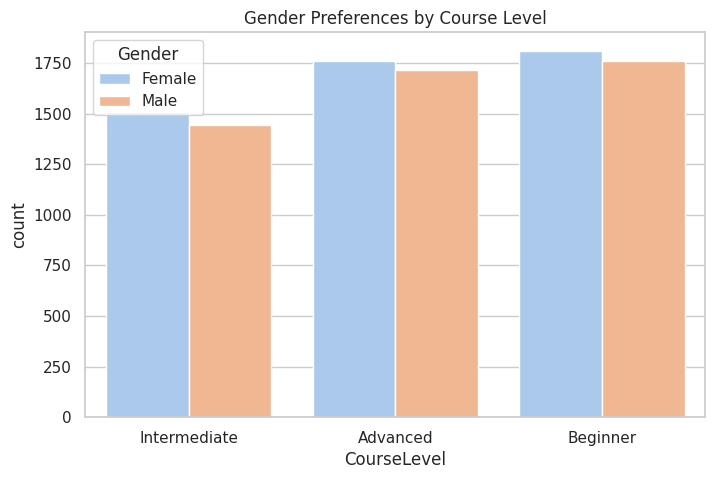

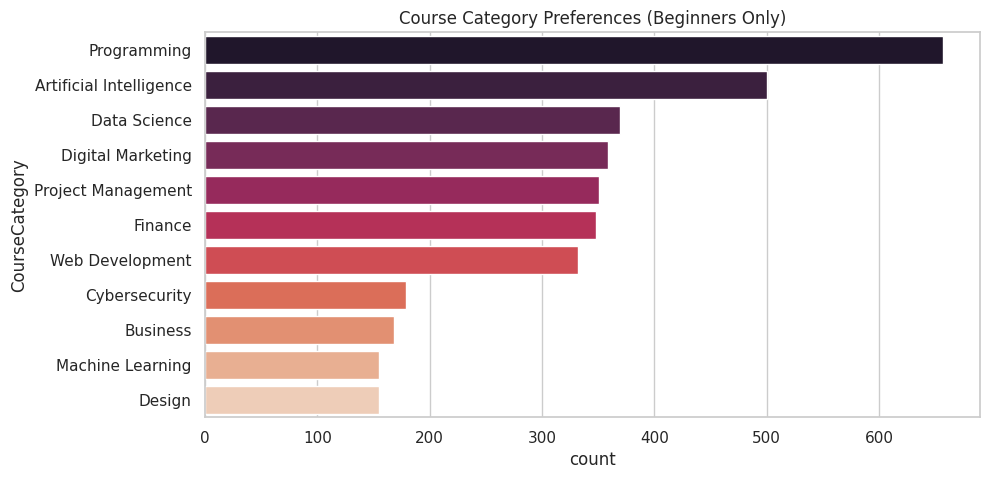

In [ ]:
# 1. Install necessary libraries (Run this cell first)
!pip install pandas matplotlib seaborn openpyxl

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# 2. Load the Dataset directly from Google Sheets
# We modify the shareable link to an export link so pandas can read it natively
sheet_url = "https://docs.google.com/spreadsheets/d/1Ts1Yjt9oiTdOeCeuJPbExNz7N3vmd0Ln/export?format=xlsx"

print("Loading data... This might take a moment.")
users_df = pd.read_excel(sheet_url, sheet_name='Users')
courses_df = pd.read_excel(sheet_url, sheet_name='Courses')
transactions_df = pd.read_excel(sheet_url, sheet_name='Transactions')

# 3. Data Integration (Merging)
# Join Users <-> Transactions <-> Courses
merged_df = transactions_df.merge(users_df, on='UserID', how='left')
merged_df = merged_df.merge(courses_df, on='CourseID', how='left')

# 4. Data Engineering (Creating Age Bands)
bins = [0, 17, 25, 35, 45, 100]
labels = ['<18', '18–25', '26–35', '36–45', '45+']
merged_df['AgeGroup'] = pd.cut(merged_df['Age'], bins=bins, labels=labels)

print("\n--- KPI SUMMARY ---")
print(f"Total Enrollments: {len(merged_df)}")
print(f"Total Unique Learners: {merged_df['UserID'].nunique()}")
print(f"Total Unique Courses: {merged_df['CourseID'].nunique()}")
print(f"Average Courses per Learner: {len(merged_df) / merged_df['UserID'].nunique():.2f}")

# 5. Visualizations for Research Paper
sns.set_theme(style="whitegrid")

# Fig 1: Age Distribution of Learners (Enrollments by Age Group)
plt.figure(figsize=(8, 5))
sns.countplot(data=merged_df, x='AgeGroup', palette='viridis', order=labels)
plt.title('Enrollments by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Enrollments')
plt.show()

# Fig 2: Gender Participation Ratio
plt.figure(figsize=(6, 5))
sns.countplot(data=merged_df, x='Gender', palette='Set2')
plt.title('Gender Participation Ratio')
plt.show()

# Fig 3: Category Popularity Index
plt.figure(figsize=(10, 5))
order = merged_df['CourseCategory'].value_counts().index
sns.countplot(data=merged_df, y='CourseCategory', palette='mako', order=order)
plt.title('Course Category Popularity')
plt.xlabel('Enrollment Count')
plt.show()

# Fig 4: Age Group vs Course Category Heatmap (Demographics × Course Preference)
plt.figure(figsize=(10, 6))
age_cat_pivot = pd.crosstab(merged_df['CourseCategory'], merged_df['AgeGroup'])
sns.heatmap(age_cat_pivot, annot=True, fmt='d', cmap='YlGnBu')
plt.title('Heatmap: Age Group vs Course Category Preference')
plt.show()

# Fig 5: Gender vs Course Level Comparisons
plt.figure(figsize=(8, 5))
sns.countplot(data=merged_df, x='CourseLevel', hue='Gender', palette='pastel')
plt.title('Gender Preferences by Course Level')
plt.show()

# Fig 6: Beginner Behavior Patterns (What categories do beginners choose?)
beginners = merged_df[merged_df['CourseLevel'].str.lower() == 'beginner']
if not beginners.empty:
    plt.figure(figsize=(10, 5))
    sns.countplot(data=beginners, y='CourseCategory', palette='rocket', order=beginners['CourseCategory'].value_counts().index)
    plt.title('Course Category Preferences (Beginners Only)')
    plt.show()

In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd
import plotly.express as px

# 1. Page Configuration
st.set_page_config(page_title="EduPro Learner Analytics", layout="wide")
st.title("🎓 EduPro: Learner Demographics & Behavior Dashboard")
st.markdown("Interactive dashboard for exploring learner intelligence and course enrollment behaviors.")

# 2. Data Loading & Caching
@st.cache_data
def load_data():
    sheet_url = "https://docs.google.com/spreadsheets/d/1Ts1Yjt9oiTdOeCeuJPbExNz7N3vmd0Ln/export?format=xlsx"
    users = pd.read_excel(sheet_url, sheet_name='Users')
    courses = pd.read_excel(sheet_url, sheet_name='Courses')
    transactions = pd.read_excel(sheet_url, sheet_name='Transactions')

    df = transactions.merge(users, on='UserID', how='left').merge(courses, on='CourseID', how='left')
    bins = [0, 17, 25, 35, 45, 100]
    labels = ['<18', '18–25', '26–35', '36–45', '45+']
    df['AgeGroup'] = pd.cut(df['Age'], bins=bins, labels=labels)
    return df

df = load_data()

# 3. Sidebar Filters
st.sidebar.header("Filter Data")
selected_age = st.sidebar.multiselect("Select Age Group", df['AgeGroup'].dropna().unique(), default=df['AgeGroup'].dropna().unique())
selected_gender = st.sidebar.multiselect("Select Gender", df['Gender'].dropna().unique(), default=df['Gender'].dropna().unique())
selected_category = st.sidebar.multiselect("Select Course Category", df['CourseCategory'].dropna().unique(), default=df['CourseCategory'].dropna().unique())
selected_level = st.sidebar.multiselect("Select Course Level", df['CourseLevel'].dropna().unique(), default=df['CourseLevel'].dropna().unique())

# Apply Filters
filtered_df = df[
    (df['AgeGroup'].isin(selected_age)) &
    (df['Gender'].isin(selected_gender)) &
    (df['CourseCategory'].isin(selected_category)) &
    (df['CourseLevel'].isin(selected_level))
]

# 4. KPIs
st.subheader("Key Performance Indicators")
col1, col2, col3, col4 = st.columns(4)
col1.metric("Total Enrollments", len(filtered_df))
col2.metric("Unique Learners", filtered_df['UserID'].nunique())
col3.metric("Avg Courses / Learner", round(len(filtered_df) / filtered_df['UserID'].nunique(), 2) if filtered_df['UserID'].nunique() > 0 else 0)
col4.metric("Top Course Category", filtered_df['CourseCategory'].mode()[0] if not filtered_df.empty else "N/A")

st.divider()

# 5. Core Modules (Visualizations)
col_a, col_b = st.columns(2)

with col_a:
    st.subheader("Demographics Overview: Age & Gender")
    fig_age = px.histogram(filtered_df, x="AgeGroup", color="Gender", barmode="group",
                           title="Enrollments by Age Group and Gender",
                           category_orders={"AgeGroup": ['<18', '18–25', '26–35', '36–45', '45+']})
    st.plotly_chart(fig_age, use_container_width=True)

with col_b:
    st.subheader("Course Category Popularity")
    cat_counts = filtered_df['CourseCategory'].value_counts().reset_index()
    cat_counts.columns = ['CourseCategory', 'Enrollments']
    fig_cat = px.bar(cat_counts, x="Enrollments", y="CourseCategory", orientation='h',
                     title="Most Popular Course Categories", color="Enrollments")
    st.plotly_chart(fig_cat, use_container_width=True)

col_c, col_d = st.columns(2)

with col_c:
    st.subheader("Gender vs Level Preferences")
    fig_level = px.histogram(filtered_df, x="CourseLevel", color="Gender", barmode="group",
                             title="Course Level Preference by Gender")
    st.plotly_chart(fig_level, use_container_width=True)

with col_d:
    st.subheader("Age vs Course Type")
    fig_type = px.density_heatmap(filtered_df, x="CourseType", y="AgeGroup",
                                  title="Heatmap: Age Group vs Course Type",
                                  category_orders={"AgeGroup": ['<18', '18–25', '26–35', '36–45', '45+']})
    st.plotly_chart(fig_type, use_container_width=True)

Writing app.py


In [ ]:
import time
import urllib

# Get the password for localtunnel
print("Password/Endpoint IP for localtunnel is:", urllib.request.urlopen('https://ipv4.icanhazip.com').read().decode('utf8').strip("\n"))

# Start Streamlit in the background
!streamlit run app.py &>/content/logs.txt &

# Wait 5 seconds for Streamlit to fully initialize before launching the tunnel
time.sleep(5)

# Start the tunnel
!npx localtunnel --port 8501

Password/Endpoint IP for localtunnel is: 34.28.204.94
⠙your url is: https://young-pants-know.loca.lt
